In [ ]:
from pathlib import Path
import os, re, json, subprocess, time, warnings, gc
import numpy as np
import pandas as pd
from scipy.sparse import hstack
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from IPython.display import display
warnings.filterwarnings("ignore")

# ===== PATH DATASET LOKAL (folder yang sama dengan notebook) =====
# Ambil direktori tempat notebook ini berada
NOTEBOOK_DIR = Path.cwd()  # Direktori saat ini
# Atau jika running dari Jupyter, gunakan path absolut
# NOTEBOOK_DIR = Path(r'D:\Mode Kompe\DIMAS TI')

# Path ke file dataset lokal
TRAIN_PATH = NOTEBOOK_DIR / 'train.csv'
TEST_PATH = NOTEBOOK_DIR / 'test.csv'

# Output (hasil CV & submission) disimpan di folder yang sama
ROOT = NOTEBOOK_DIR / 'output'
ROOT.mkdir(parents=True, exist_ok=True)

# Cek apakah file train.csv ada
if not TRAIN_PATH.exists():
    raise FileNotFoundError(
        f'train.csv tidak ditemukan di {NOTEBOOK_DIR}.\n'
        f'Pastikan file train.csv ada di folder yang sama dengan notebook ini.'
    )

print('NOTEBOOK_DIR:', NOTEBOOK_DIR)
print('TRAIN_PATH:', TRAIN_PATH)
train_raw = pd.read_csv(TRAIN_PATH)
print('Official train shape:', train_raw.shape)
display(train_raw.head(3))

if TEST_PATH.exists():
    print('\nTEST_PATH:', TEST_PATH)
    test_raw = pd.read_csv(TEST_PATH)
    print('Official test shape:', test_raw.shape)
else:
    print('\ntest.csv tidak ditemukan - submission akan dilewati.')
    test_raw = None

In [2]:
MIME_URL = 'https://github.com/scrosseye/mime_dataset.git'
MIME_DIR = ROOT/'mime_dataset'

# Clone butuh internet. Jika Internet Kaggle nonaktif, langkah audit MIME dilewati
# (tidak memengaruhi training/CV pada train.csv resmi).
if not MIME_DIR.exists():
    try:
        subprocess.run(['git','clone','--depth','1',MIME_URL,str(MIME_DIR)],
                       check=True, capture_output=True, text=True, timeout=120)
    except Exception as e:
        print('Clone MIME dilewati (internet nonaktif / repo tidak dapat diakses):', type(e).__name__)

TABULAR_EXTS = {'.csv','.tsv','.parquet','.jsonl','.json','.xlsx'}
files = []
if MIME_DIR.exists():
    for p in MIME_DIR.rglob('*'):
        if p.is_file() and '.git' not in p.parts and p.suffix.lower() in TABULAR_EXTS:
            files.append({'path':str(p.relative_to(MIME_DIR)), 'bytes':p.stat().st_size})
file_index = pd.DataFrame(files, columns=['path','bytes']).sort_values('path').reset_index(drop=True)
display(file_index)
print('Do not assume every labelled file is safe for training. Files named test, benchmark, holdout, private, eval, or validation are not training augmentation by default.')

,path,bytes
0,dataset_minus_700_for_github.csv,13354420


Do not assume every labelled file is safe for training. Files named test, benchmark, holdout, private, eval, or validation are not training augmentation by default.


In [3]:
def read_table(path):
    p = Path(path)
    if p.suffix.lower()=='.csv': return pd.read_csv(p, low_memory=False)
    if p.suffix.lower()=='.tsv': return pd.read_csv(p, sep='\t', low_memory=False)
    if p.suffix.lower()=='.parquet': return pd.read_parquet(p)
    if p.suffix.lower()=='.jsonl': return pd.read_json(p, lines=True)
    if p.suffix.lower()=='.json':
        try: return pd.read_json(p, lines=True)
        except ValueError: return pd.read_json(p)
    if p.suffix.lower()=='.xlsx': return pd.read_excel(p)
    raise ValueError(p.suffix)

EXCLUDE_TOKENS = ('test','testing','benchmark','holdout','heldout','private','eval','evaluation','validation','valid')
def looks_like_train(path):
    s = str(path).lower()
    return 'train' in s and not any(t in s for t in EXCLUDE_TOKENS)

candidate_paths = [MIME_DIR/row['path'] for _,row in file_index.iterrows() if looks_like_train(row['path'])]
print('Training-name candidates:', [str(p.relative_to(MIME_DIR)) for p in candidate_paths])
for p in candidate_paths:
    try:
        tmp = read_table(p)
        print('\nFILE:', p.relative_to(MIME_DIR), '| shape:', tmp.shape, '| columns:', list(tmp.columns))
        display(tmp.head(2))
    except Exception as e:
        print('Could not read', p, repr(e))

# If the repository uses different split names, set MIME_TRAIN_PATH manually after reviewing file_index.
MIME_TRAIN_PATH = None  # Example: MIME_DIR/'data'/'train.csv'
print('Set MIME_TRAIN_PATH only after verifying the file is a training split in the repository README.')

Training-name candidates: []
Set MIME_TRAIN_PATH only after verifying the file is a training split in the repository README.


In [4]:
def norm_text(x):
    if pd.isna(x): return ''
    return re.sub(r'\s+',' ',str(x).replace('\u200b',' ').replace('\ufeff',' ')).strip().lower()

def find_col(df, aliases):
    lookup = {re.sub(r'[^a-z0-9]+','',str(c).lower()):c for c in df.columns}
    for a in aliases:
        key = re.sub(r'[^a-z0-9]+','',a.lower())
        if key in lookup: return lookup[key]
    return None

def audit_mime_file(path, official):
    ext = read_table(path)
    e_exp = find_col(ext,['StudentExplanation','student_explanation','explanation','response','text'])
    o_exp = find_col(official,['StudentExplanation','student_explanation','explanation'])
    if not e_exp or not o_exp:
        return {'path':str(path),'shape':ext.shape,'columns':list(ext.columns),'error':'Could not map explanation column'}
    e = ext.copy(); o = official.copy()
    e['__exp_norm'] = e[e_exp].map(norm_text); o['__exp_norm'] = o[o_exp].map(norm_text)
    summary = {'path':str(path),'rows':len(e),'columns':list(ext.columns),
               'exact_explanation_overlap_rows':int(e['__exp_norm'].isin(set(o['__exp_norm'])).sum()),
               'duplicate_explanation_rows_within_file':int(e['__exp_norm'].duplicated().sum()),
               'possible_provenance_columns':[c for c in ext.columns if any(t in str(c).lower() for t in ['synthetic','augment','source','origin','parent','original_id'])]}
    q_e=find_col(e,['QuestionId','question_id','qid']); q_o=find_col(o,['QuestionId','question_id','qid'])
    a_e=find_col(e,['MC_Answer','mc_answer','answer','selected_answer']); a_o=find_col(o,['MC_Answer','mc_answer','answer','selected_answer'])
    if q_e and q_o and a_e and a_o:
        e['__key']=e[q_e].astype(str)+'||'+e[a_e].astype(str)+'||'+e['__exp_norm']
        o['__key']=o[q_o].astype(str)+'||'+o[a_o].astype(str)+'||'+o['__exp_norm']
        summary['exact_question_answer_explanation_overlap_rows']=int(e['__key'].isin(set(o['__key'])).sum())
    return summary

if 'train_raw' in globals() and MIME_TRAIN_PATH is not None:
    MIME_TRAIN_PATH = Path(MIME_TRAIN_PATH)
    if not MIME_TRAIN_PATH.exists(): raise FileNotFoundError(MIME_TRAIN_PATH)
    if not looks_like_train(str(MIME_TRAIN_PATH.relative_to(MIME_DIR))):
        raise ValueError('Selected file name/path is not clearly training-only. Re-check split provenance.')
    mime_audit = audit_mime_file(MIME_TRAIN_PATH, train_raw)
    print(json.dumps(mime_audit, indent=2, default=str))
else:
    print('Audit not run yet. Review file_index, then set MIME_TRAIN_PATH to an explicitly verified training file and rerun this cell.')

Audit not run yet. Review file_index, then set MIME_TRAIN_PATH to an explicitly verified training file and rerun this cell.


In [5]:
def target_full(df):
    mis=df['Misconception'].fillna('NA').astype(str).str.strip().replace({'':'NA','nan':'NA','None':'NA'})
    mis=mis.where(df['Category'].astype(str).str.endswith('_Misconception'),'NA')
    return (df['Category'].astype(str).str.strip()+':'+mis).to_numpy(dtype=str)

def target_reduced(df):
    out=[]
    for cat,mis in zip(df['Category'].astype(str),df['Misconception']):
        if cat.endswith('_Misconception'):
            mis='' if pd.isna(mis) else str(mis).strip()
            if mis.lower()=='wrong_fraction': mis='Wrong_Fraction'
            out.append(mis)
        elif cat.endswith('_Correct'): out.append('Correct')
        else: out.append('Neither')
    return np.asarray(out,dtype=str)

def text_context(df):
    q=df['QuestionText'].fillna('').astype(str); a=df['MC_Answer'].fillna('').astype(str); e=df['StudentExplanation'].fillna('').astype(str)
    return ('question: '+q+' answer: '+a+' explanation: '+e).to_numpy(dtype=str)

def answer_key_fit(df):
    tmp=df[['QuestionId','MC_Answer','Category']].copy()
    tmp['true']=tmp['Category'].astype(str).str.startswith('True_').astype(int)
    agg=tmp.groupby(['QuestionId','MC_Answer'])['true'].agg(['mean','sum','count']).reset_index()
    agg=agg.sort_values(['QuestionId','mean','count','sum'],ascending=[True,False,False,False])
    return agg.drop_duplicates('QuestionId').set_index('QuestionId')['MC_Answer'].to_dict()

def score_map3(y, pred):
    y=np.asarray(y,dtype=str); pred=np.asarray(pred,dtype=str); rr=np.zeros(len(y),float)
    for rank in range(min(3,pred.shape[1])):
        hit=(pred[:,rank]==y)&(rr==0); rr[hit]=1/(rank+1)
    return {'MAP@3':float(rr.mean()),'Top1 Accuracy':float((pred[:,0]==y).mean()),'Hit@3':float((pred==y[:,None]).any(axis=1).mean())}

def run_official_cv(df, qa_weight=0.5, tol=0.1):
    df=df.copy()
    for c in ['QuestionText','MC_Answer','StudentExplanation']:
        df[c]=df[c].fillna('').astype(str).str.replace(r'\s+',' ',regex=True).str.strip()
    yfull=target_full(df); yred=target_reduced(df)
    groups=df['StudentExplanation'].map(norm_text).to_numpy()
    cv=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=42)
    rows=[]
    for fold,(ti,vi) in enumerate(cv.split(df,df['Category'].astype(str),groups=groups),1):
        tr=df.iloc[ti].reset_index(drop=True); va=df.iloc[vi].reset_index(drop=True)

        # Cek kebocoran berdasarkan grup penjelasan siswa (bukan QuestionId).
        # Overlap QuestionId antar-fold itu wajar karena soal yang sama
        # juga muncul di data uji dan dipakai sebagai fitur.
        train_groups = set(groups[ti])
        valid_groups = set(groups[vi])
        overlap = train_groups.intersection(valid_groups)

        print(
            f"Fold {fold}: "
            f"train={len(tr)} baris, validasi={len(va)} baris, "
            f"overlap grup penjelasan={len(overlap)}; "
            f"soal train={tr['QuestionId'].nunique()}, soal validasi={va['QuestionId'].nunique()}"
        )

        assert len(overlap) == 0, (
            f"Ada penjelasan yang bocor antar-fold: {len(overlap)} grup"
        )

        word=TfidfVectorizer(ngram_range=(1,2),min_df=2,max_df=.995,sublinear_tf=True,strip_accents='unicode',token_pattern=r'(?u)\b\w+\b',max_features=30000,dtype=np.float32)
        Xwtr=word.fit_transform(text_context(tr)); Xwva=word.transform(text_context(va))
        char=TfidfVectorizer(analyzer='char_wb',ngram_range=(3,5),min_df=2,max_df=.999,sublinear_tf=True,max_features=5000,dtype=np.float32)
        Xctr=char.fit_transform(tr['StudentExplanation']); Xcva=char.transform(va['StudentExplanation'])
        qid=OneHotEncoder(handle_unknown='ignore',dtype=np.float32)
        Xqtr=qid.fit_transform(tr[['QuestionId']].astype(str)); Xqva=qid.transform(va[['QuestionId']].astype(str))
        qa=OneHotEncoder(handle_unknown='ignore',dtype=np.float32)
        Xqatr=qa.fit_transform((tr.QuestionId.astype(str)+'|||'+tr.MC_Answer).to_frame('qa'))
        Xqava=qa.transform((va.QuestionId.astype(str)+'|||'+va.MC_Answer).to_frame('qa'))
        Xtr=hstack([Xwtr,Xctr*0.5,Xqtr*0.35,Xqatr*qa_weight],format='csr',dtype=np.float32)
        Xva=hstack([Xwva,Xcva*0.5,Xqva*0.35,Xqava*qa_weight],format='csr',dtype=np.float32)
        for mat in (Xtr,Xva): mat.sum_duplicates(); mat.sort_indices()
        model=LogisticRegression(C=1.0,solver='saga',max_iter=100,tol=tol,random_state=42)
        t0=time.time(); model.fit(Xtr,yred[ti]); fit_seconds=time.time()-t0
        prob=model.predict_proba(Xva); ix=np.argsort(-prob,axis=1,kind='mergesort')[:,:3]; red=np.asarray(model.classes_)[ix]
        key=answer_key_fit(tr); prefixes=np.array(['True' if q in key and key[q]==a else 'False' for q,a in zip(va.QuestionId,va.MC_Answer)])
        variants={q:g['Misconception'].value_counts().idxmax() for q,g in tr.loc[tr['Misconception'].fillna('').str.lower().eq('wrong_fraction')].groupby('QuestionId')}
        qids=va.QuestionId.to_numpy(); top=np.empty(red.shape,dtype=object)
        for i in range(len(va)):
            for j in range(3):
                lbl=red[i,j]
                if lbl=='Correct': out=f'{prefixes[i]}_Correct:NA'
                elif lbl=='Neither': out=f'{prefixes[i]}_Neither:NA'
                else:
                    m=variants.get(qids[i],'Wrong_Fraction') if lbl=='Wrong_Fraction' else lbl
                    out=f'{prefixes[i]}_Misconception:{m}'
                top[i,j]=out
        metrics=score_map3(yfull[vi],top.astype(str))
        true_prefix=np.where(va['Category'].astype(str).str.startswith('True_'),'True','False')
        key_acc=float((prefixes==true_prefix).mean())
        rows.append({'fold':fold,'qa_weight':qa_weight,'tol':tol,'n_iter':int(np.max(model.n_iter_)),'fit_seconds':round(fit_seconds,2),
                     'answer_key_accuracy':key_acc,'answer_key_coverage':float(va.QuestionId.isin(key).mean()),**metrics})
        print(f'fold {fold}/5: MAP@3={metrics["MAP@3"]:.6f}; Top1={metrics["Top1 Accuracy"]:.4f}; Hit@3={metrics["Hit@3"]:.4f}; key_acc={key_acc:.5f}',flush=True)
    return pd.DataFrame(rows)

cv_results = run_official_cv(train_raw, qa_weight=0.5, tol=0.1)
display(cv_results)
print('Mean metrics:')
display(cv_results[['MAP@3','Top1 Accuracy','Hit@3','answer_key_accuracy']].agg(['mean','std']))
cv_results.to_csv(ROOT/'DIMAS_TI_MIME_Audit_CV_results.csv',index=False)

Fold 1: train=29356 baris, validasi=7340 baris, overlap grup penjelasan=0; soal train=15, soal validasi=15
fold 1/5: MAP@3=0.911762; Top1=0.8334; Hit@3=0.9956; key_acc=0.99918
Fold 2: train=29357 baris, validasi=7339 baris, overlap grup penjelasan=0; soal train=15, soal validasi=15
fold 2/5: MAP@3=0.911864; Top1=0.8343; Hit@3=0.9939; key_acc=0.99945
Fold 3: train=29357 baris, validasi=7339 baris, overlap grup penjelasan=0; soal train=15, soal validasi=15
fold 3/5: MAP@3=0.913249; Top1=0.8365; Hit@3=0.9951; key_acc=0.99973
Fold 4: train=29357 baris, validasi=7339 baris, overlap grup penjelasan=0; soal train=15, soal validasi=15
fold 4/5: MAP@3=0.912499; Top1=0.8349; Hit@3=0.9950; key_acc=0.99945
Fold 5: train=29357 baris, validasi=7339 baris, overlap grup penjelasan=0; soal train=15, soal validasi=15
fold 5/5: MAP@3=0.910978; Top1=0.8321; Hit@3=0.9948; key_acc=0.99973


,fold,qa_weight,tol,n_iter,fit_seconds,answer_key_accuracy,answer_key_coverage,MAP@3,Top1 Accuracy,Hit@3
0,1,0.5,0.1,3,3.76,0.999183,1.0,0.911762,0.833379,0.995640
1,2,0.5,0.1,4,5.25,0.999455,1.0,0.911864,0.834310,0.993868
2,3,0.5,0.1,4,4.86,0.999727,1.0,0.913249,0.836490,0.995095
3,4,0.5,0.1,4,5.42,0.999455,1.0,0.912499,0.834855,0.994958
4,5,0.5,0.1,4,5.66,0.999727,1.0,0.910978,0.832130,0.994822


Mean metrics:


,MAP@3,Top1 Accuracy,Hit@3,answer_key_accuracy
mean,0.912070,0.834233,0.994877,0.999509
std,0.000852,0.001631,0.000644,0.000228


In [6]:
# ===== CELL 7: Optimasi TF-IDF + Logistic Regression (setelan cepat) =====

import gc
import os
import time
import warnings
import numpy as np
import pandas as pd

from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore")

# ============================ KONFIGURASI ============================
# ROOT dan train_raw menggunakan variabel dari cell sebelumnya.
# Tidak mendefinisikan ulang ROOT dan tidak membaca ulang train.csv.

N_SPLITS = 3
SEED = 42
MAX_ITER = 300

RUN_CV = True
RUN_FINAL_SUBMISSION = True

# Tiga eksperimen (E0 dibuang agar lebih cepat).
EXPERIMENTS = [
    {
        "name": "E1_character_features",
        "word_ngram": (1, 2),
        "word_min_df": 2,
        "word_max_features": 50000,
        "char_ngram": (3, 6),
        "char_min_df": 2,
        "char_max_features": 20000,
        "char_weight": 0.5,
        "qid_weight": 0.35,
        "qa_weight": 0.5,
        "C": 1.0,
        "tol": 1e-2,
        "class_weight": None,
    },
    {
        "name": "E2_regularization",
        "word_ngram": (1, 2),
        "word_min_df": 2,
        "word_max_features": 50000,
        "char_ngram": (3, 6),
        "char_min_df": 2,
        "char_max_features": 20000,
        "char_weight": 0.5,
        "qid_weight": 0.35,
        "qa_weight": 0.5,
        "C": 0.3,
        "tol": 1e-2,
        "class_weight": None,
    },
    {
        "name": "E3_balanced_classes",
        "word_ngram": (1, 2),
        "word_min_df": 2,
        "word_max_features": 50000,
        "char_ngram": (3, 6),
        "char_min_df": 2,
        "char_max_features": 20000,
        "char_weight": 0.5,
        "qid_weight": 0.35,
        "qa_weight": 0.5,
        "C": 0.3,
        "tol": 1e-2,
        "class_weight": "balanced",
    },
]

# Pastikan variabel dan fungsi dari cell sebelumnya tersedia.
required_vars = ["ROOT", "train_raw"]
missing_vars = [v for v in required_vars if v not in globals()]

if missing_vars:
    raise RuntimeError(
        f"Variabel belum tersedia: {missing_vars}. "
        "Jalankan cell sebelumnya terlebih dahulu."
    )

required_funcs = [
    "target_full",
    "target_reduced",
    "answer_key_fit",
    "text_context",
    "norm_text",
    "score_map3",
]

missing_funcs = [
    f for f in required_funcs
    if f not in globals() or not callable(globals()[f])
]

if missing_funcs:
    raise RuntimeError(
        f"Fungsi dari cell sebelumnya belum tersedia: {missing_funcs}"
    )

# ROOT hanya digunakan sebagai lokasi output.
# Mendukung ROOT bertipe string maupun Path.
OUTPUT_DIR = str(ROOT)
os.makedirs(OUTPUT_DIR, exist_ok=True)


# ============================ UTILITAS ============================

def _clean_model_df(df, require_labels=True):
    """
    require_labels=True  : data training/validasi (wajib ada Category & Misconception).
    require_labels=False : data test (tidak punya kolom label).
    """
    df = df.copy()

    required = [
        "QuestionId",
        "QuestionText",
        "MC_Answer",
        "StudentExplanation",
    ]

    if require_labels:
        required += ["Category", "Misconception"]

    missing = [c for c in required if c not in df.columns]

    if missing:
        raise ValueError(f"Kolom dataset tidak tersedia: {missing}")

    for col in ["QuestionText", "MC_Answer", "StudentExplanation"]:
        df[col] = (
            df[col]
            .fillna("")
            .astype(str)
            .str.replace(r"\s+", " ", regex=True)
            .str.strip()
        )

    return df


def _make_onehot():
    # Kompatibel dengan beberapa versi scikit-learn.
    try:
        return OneHotEncoder(
            handle_unknown="ignore",
            dtype=np.float32,
            sparse_output=True,
        )
    except TypeError:
        return OneHotEncoder(
            handle_unknown="ignore",
            dtype=np.float32,
            sparse=True,
        )


def _build_variants(train_df):
    """
    Mengambil variasi label Wrong_Fraction dari training fold saja.
    """
    mis = (
        train_df["Misconception"]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    subset = train_df.loc[
        mis.str.lower().eq("wrong_fraction")
    ].copy()

    if subset.empty:
        return {}

    return {
        qid: group["Misconception"].value_counts().idxmax()
        for qid, group in subset.groupby("QuestionId")
    }


def _map_reduced_to_full(reduced_top3, pred_df, answer_key, variants):
    """
    Mengubah tiga kandidat label internal menjadi label final.
    Prefix True/False ditentukan dari answer key training fold.
    """
    prefixes = np.array([
        (
            "True" if answer_key[q] == a else "False"
        ) if q in answer_key else "False"
        for q, a in zip(
            pred_df["QuestionId"],
            pred_df["MC_Answer"],
        )
    ])

    qids = pred_df["QuestionId"].to_numpy()
    output = np.empty(reduced_top3.shape, dtype=object)

    for i in range(len(pred_df)):
        for j in range(reduced_top3.shape[1]):
            label = str(reduced_top3[i, j])

            if label == "Correct":
                final_label = f"{prefixes[i]}_Correct:NA"

            elif label == "Neither":
                final_label = f"{prefixes[i]}_Neither:NA"

            else:
                misconception = (
                    variants.get(qids[i], "Wrong_Fraction")
                    if label == "Wrong_Fraction"
                    else label
                )

                final_label = (
                    f"{prefixes[i]}_Misconception:{misconception}"
                )

            output[i, j] = final_label

    return output.astype(str)


# ============================ FITUR ============================

def _fit_transform_features(train_df, pred_df, cfg):
    """
    Word TF-IDF + Character TF-IDF + QuestionId + QuestionId/MC_Answer.
    Semua encoder hanya di-fit pada data training.
    """
    train_text = text_context(train_df)
    pred_text = text_context(pred_df)

    # 1. Word TF-IDF
    word_vectorizer = TfidfVectorizer(
        analyzer="word",
        ngram_range=cfg["word_ngram"],
        min_df=cfg["word_min_df"],
        max_df=0.995,
        sublinear_tf=True,
        strip_accents="unicode",
        token_pattern=r"(?u)\b\w+\b",
        max_features=cfg["word_max_features"],
        dtype=np.float32,
    )

    Xw_train = word_vectorizer.fit_transform(train_text)
    Xw_pred = word_vectorizer.transform(pred_text)

    # 2. Character TF-IDF dari penjelasan siswa
    char_vectorizer = TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=cfg["char_ngram"],
        min_df=cfg["char_min_df"],
        max_df=0.999,
        sublinear_tf=True,
        max_features=cfg["char_max_features"],
        dtype=np.float32,
    )

    Xc_train = char_vectorizer.fit_transform(
        train_df["StudentExplanation"].astype(str)
    )
    Xc_pred = char_vectorizer.transform(
        pred_df["StudentExplanation"].astype(str)
    )

    # 3. Fitur QuestionId
    qid_encoder = _make_onehot()

    Xq_train = qid_encoder.fit_transform(
        train_df[["QuestionId"]].astype(str)
    )
    Xq_pred = qid_encoder.transform(
        pred_df[["QuestionId"]].astype(str)
    )

    # 4. Fitur kombinasi QuestionId dan MC_Answer
    train_qa = (
        train_df["QuestionId"].astype(str)
        + "|||"
        + train_df["MC_Answer"].astype(str)
    ).to_frame("qa")

    pred_qa = (
        pred_df["QuestionId"].astype(str)
        + "|||"
        + pred_df["MC_Answer"].astype(str)
    ).to_frame("qa")

    qa_encoder = _make_onehot()
    Xqa_train = qa_encoder.fit_transform(train_qa)
    Xqa_pred = qa_encoder.transform(pred_qa)

    # Gabungkan fitur dalam sparse matrix.
    X_train = hstack(
        [
            Xw_train,
            Xc_train * cfg["char_weight"],
            Xq_train * cfg["qid_weight"],
            Xqa_train * cfg["qa_weight"],
        ],
        format="csr",
        dtype=np.float32,
    )

    X_pred = hstack(
        [
            Xw_pred,
            Xc_pred * cfg["char_weight"],
            Xq_pred * cfg["qid_weight"],
            Xqa_pred * cfg["qa_weight"],
        ],
        format="csr",
        dtype=np.float32,
    )

    X_train.sum_duplicates()
    X_train.sort_indices()
    X_pred.sum_duplicates()
    X_pred.sort_indices()

    return X_train, X_pred


# ============================ MODEL ============================

def _fit_predict_top3(train_df, pred_df, cfg, seed=SEED):
    train_df = _clean_model_df(train_df)
    # pred_df bisa data test (tanpa Category/Misconception).
    pred_df = _clean_model_df(pred_df, require_labels=False)

    y_train = target_reduced(train_df)

    # Answer key hanya menggunakan training fold.
    answer_key = answer_key_fit(train_df)
    variants = _build_variants(train_df)

    X_train, X_pred = _fit_transform_features(
        train_df,
        pred_df,
        cfg,
    )

    model = LogisticRegression(
        C=cfg["C"],
        solver="lbfgs",
        max_iter=MAX_ITER,
        tol=cfg["tol"],
        class_weight=cfg["class_weight"],
        random_state=seed,
    )

    start = time.time()
    model.fit(X_train, y_train)
    fit_seconds = time.time() - start

    probabilities = model.predict_proba(X_pred)

    # Urutkan probabilitas tertinggi untuk mendapatkan top-3.
    top_indices = np.argsort(
        -probabilities,
        axis=1,
        kind="mergesort",
    )[:, :min(3, probabilities.shape[1])]

    reduced_top3 = np.asarray(
        model.classes_,
        dtype=str,
    )[top_indices]

    final_top3 = _map_reduced_to_full(
        reduced_top3,
        pred_df,
        answer_key,
        variants,
    )

    info = {
        "fit_seconds": round(fit_seconds, 2),
        "n_iter": int(np.max(model.n_iter_)),
        "converged": bool(np.max(model.n_iter_) < MAX_ITER),
        "answer_key": answer_key,
    }

    del X_train, X_pred, model, probabilities
    gc.collect()

    return final_top3, info


# ============================ CROSS-VALIDATION ============================

def _run_cv_experiment(df, cfg):
    df = _clean_model_df(df)
    y_full = target_full(df)

    groups = (
        df["StudentExplanation"]
        .map(norm_text)
        .to_numpy()
    )

    cv = StratifiedGroupKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=SEED,
    )

    rows = []

    for fold, (train_idx, valid_idx) in enumerate(
        cv.split(
            df,
            df["Category"].astype(str),
            groups=groups,
        ),
        start=1,
    ):
        train_df = df.iloc[train_idx].reset_index(drop=True)
        valid_df = df.iloc[valid_idx].reset_index(drop=True)

        overlap = (
            set(groups[train_idx])
            & set(groups[valid_idx])
        )

        assert not overlap, (
            f"Group leakage terdeteksi: {len(overlap)} grup."
        )

        print(
            f"\n{cfg['name']} | Fold {fold}/{N_SPLITS} "
            f"| train={len(train_df)} "
            f"| validasi={len(valid_df)} "
            f"| overlap={len(overlap)}",
            flush=True,
        )

        pred_top3, info = _fit_predict_top3(
            train_df,
            valid_df,
            cfg,
            seed=SEED + fold,
        )

        metrics = score_map3(
            y_full[valid_idx],
            pred_top3,
        )

        key = info["answer_key"]

        prefix_pred = np.array([
            (
                "True" if key[q] == a else "False"
            ) if q in key else "False"
            for q, a in zip(
                valid_df["QuestionId"],
                valid_df["MC_Answer"],
            )
        ])

        prefix_true = np.where(
            valid_df["Category"]
            .astype(str)
            .str.startswith("True_"),
            "True",
            "False",
        )

        key_acc = float(
            (prefix_pred == prefix_true).mean()
        )

        row = {
            "experiment": cfg["name"],
            "fold": fold,
            "C": cfg["C"],
            "tol": cfg["tol"],
            "char_weight": cfg["char_weight"],
            "qid_weight": cfg["qid_weight"],
            "qa_weight": cfg["qa_weight"],
            "class_weight": str(cfg["class_weight"]),
            "n_iter": info["n_iter"],
            "converged": info["converged"],
            "fit_seconds": info["fit_seconds"],
            "answer_key_accuracy": key_acc,
            "answer_key_coverage": float(
                valid_df["QuestionId"].isin(key).mean()
            ),
            **metrics,
        }

        rows.append(row)

        print(
            f"MAP@3={metrics['MAP@3']:.6f} | "
            f"Top1={metrics['Top1 Accuracy']:.4f} | "
            f"Hit@3={metrics['Hit@3']:.4f} | "
            f"key_acc={key_acc:.5f} | "
            f"iter={info['n_iter']} | "
            f"fit={info['fit_seconds']}s",
            flush=True,
        )

    return pd.DataFrame(rows)


# ============================ JALANKAN EKSPERIMEN ============================

train_data = _clean_model_df(train_raw)

print("Jumlah baris:", len(train_data))
print("QuestionId unik:", train_data["QuestionId"].nunique())
print("Kelas target final:", len(set(target_full(train_data))))
print("Kelas target reduced:", len(set(target_reduced(train_data))))

print("\nDistribusi kelas target final:")
display(
    pd.Series(target_full(train_data))
    .value_counts()
    .rename_axis("Label")
    .reset_index(name="Jumlah")
)

cv_results_all = []
summary_df = pd.DataFrame()

if RUN_CV:
    for cfg in EXPERIMENTS:
        result = _run_cv_experiment(train_data, cfg)
        cv_results_all.append(result)

        # Simpan hasil setiap eksperimen agar hasil tetap tersedia
        # jika runtime terhenti sebelum seluruh eksperimen selesai.
        partial_results = pd.concat(
            cv_results_all,
            ignore_index=True,
        )

        partial_results.to_csv(
            os.path.join(
                OUTPUT_DIR,
                "DIMAS_TI_LR_CV_fold_results.csv",
            ),
            index=False,
        )

    cv_results_all = pd.concat(
        cv_results_all,
        ignore_index=True,
    )

    summary_rows = []

    for name, group in cv_results_all.groupby("experiment"):
        row = {"experiment": name}

        for metric in [
            "MAP@3",
            "Top1 Accuracy",
            "Hit@3",
            "answer_key_accuracy",
            "fit_seconds",
        ]:
            row[f"{metric}_mean"] = group[metric].mean()
            row[f"{metric}_std"] = group[metric].std(ddof=1)

        summary_rows.append(row)

    summary_df = pd.DataFrame(summary_rows).sort_values(
        "MAP@3_mean",
        ascending=False,
    )

    summary_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "DIMAS_TI_LR_CV_summary.csv",
        ),
        index=False,
    )

    print("\n=== RINGKASAN EKSPERIMEN ===")
    display(summary_df)

    print(
        "Detail fold:",
        os.path.join(
            OUTPUT_DIR,
            "DIMAS_TI_LR_CV_fold_results.csv",
        ),
    )

    print(
        "Ringkasan:",
        os.path.join(
            OUTPUT_DIR,
            "DIMAS_TI_LR_CV_summary.csv",
        ),
    )

    best_name = summary_df.iloc[0]["experiment"]

    best_cfg = next(
        cfg for cfg in EXPERIMENTS
        if cfg["name"] == best_name
    )

    print(
        "\nKonfigurasi terbaik berdasarkan MAP@3:",
        best_name,
    )

else:
    best_cfg = EXPERIMENTS[0]


# ============================ FINAL SUBMISSION ============================

if RUN_FINAL_SUBMISSION:
    # Prioritaskan test_raw jika sudah tersedia di cell sebelumnya.
    if "test_raw" in globals() and isinstance(test_raw, pd.DataFrame):
        test_data = test_raw.copy()

    else:
        test_path = os.path.join(OUTPUT_DIR, "test.csv")

        if os.path.exists(test_path):
            test_data = pd.read_csv(
                test_path,
                low_memory=False,
            )
        else:
            test_data = None
            print(
                "\nSubmission dilewati: test_raw tidak tersedia "
                "dan test.csv tidak ditemukan pada ROOT."
            )

    if test_data is not None:
        # Data test tidak punya kolom Category/Misconception.
        test_data = _clean_model_df(test_data, require_labels=False)

        if "row_id" not in test_data.columns:
            raise ValueError(
                "Kolom row_id tidak ditemukan pada dataset test."
            )

        pred_test, final_info = _fit_predict_top3(
            train_data,
            test_data,
            best_cfg,
            seed=SEED,
        )

        submission = pd.DataFrame({
            "row_id": test_data["row_id"],
            "Category:Misconception": [
                " ".join(row)
                for row in pred_test
            ],
        })

        submission_path = os.path.join(
            OUTPUT_DIR,
            "DIMAS_TI_submission.csv",
        )

        submission.to_csv(
            submission_path,
            index=False,
        )

        print("\nSubmission tersimpan:", submission_path)
        print("Jumlah baris submission:", len(submission))
        print("Konfigurasi final:", best_cfg)
        print(
            "Iterasi model:",
            final_info["n_iter"],
            "| waktu pelatihan:",
            final_info["fit_seconds"],
            "detik",
        )

Jumlah baris: 36696
QuestionId unik: 15
Kelas target final: 65
Kelas target reduced: 36

Distribusi kelas target final:


,Label,Jumlah
0,True_Correct:NA,14802
1,False_Neither:NA,6542
2,True_Neither:NA,5265
3,False_Misconception:Incomplete,1446
4,False_Misconception:Additive,891
...,...,...
60,True_Misconception:Not_variable,1
61,True_Misconception:Whole_numbers_larger,1
62,True_Misconception:Adding_across,1
63,True_Misconception:Longer_is_bigger,1



E1_character_features | Fold 1/3 | train=24464 | validasi=12232 | overlap=0
MAP@3=0.864495 | Top1=0.7623 | Hit@3=0.9735 | key_acc=0.99959 | iter=10 | fit=6.9s

E1_character_features | Fold 2/3 | train=24464 | validasi=12232 | overlap=0
MAP@3=0.865667 | Top1=0.7673 | Hit@3=0.9700 | key_acc=0.99935 | iter=10 | fit=6.96s

E1_character_features | Fold 3/3 | train=24464 | validasi=12232 | overlap=0
MAP@3=0.865449 | Top1=0.7637 | Hit@3=0.9746 | key_acc=0.99959 | iter=10 | fit=6.82s

E2_regularization | Fold 1/3 | train=24464 | validasi=12232 | overlap=0
MAP@3=0.864372 | Top1=0.7623 | Hit@3=0.9738 | key_acc=0.99959 | iter=10 | fit=6.59s

E2_regularization | Fold 2/3 | train=24464 | validasi=12232 | overlap=0
MAP@3=0.865449 | Top1=0.7680 | Hit@3=0.9697 | key_acc=0.99935 | iter=10 | fit=6.76s

E2_regularization | Fold 3/3 | train=24464 | validasi=12232 | overlap=0
MAP@3=0.865176 | Top1=0.7645 | Hit@3=0.9741 | key_acc=0.99959 | iter=10 | fit=6.86s

E3_balanced_classes | Fold 1/3 | train=24464 |

,experiment,MAP@3_mean,MAP@3_std,Top1 Accuracy_mean,Top1 Accuracy_std,Hit@3_mean,Hit@3_std,answer_key_accuracy_mean,answer_key_accuracy_std,fit_seconds_mean,fit_seconds_std
0,E1_character_features,0.865203,0.000623,0.764443,0.002586,0.972695,0.002396,0.999509,0.000142,6.893333,0.070238
1,E2_regularization,0.864999,0.000560,0.764906,0.002886,0.972504,0.002460,0.999509,0.000142,6.736667,0.136504
2,E3_balanced_classes,0.564498,0.011560,0.390560,0.008473,0.832761,0.012071,0.999509,0.000142,5.826667,0.276104


Detail fold: d:\Mode Kompe\DIMAS TI\output\DIMAS_TI_LR_CV_fold_results.csv
Ringkasan: d:\Mode Kompe\DIMAS TI\output\DIMAS_TI_LR_CV_summary.csv

Konfigurasi terbaik berdasarkan MAP@3: E1_character_features

Submission tersimpan: d:\Mode Kompe\DIMAS TI\output\DIMAS_TI_submission.csv
Jumlah baris submission: 3
Konfigurasi final: {'name': 'E1_character_features', 'word_ngram': (1, 2), 'word_min_df': 2, 'word_max_features': 50000, 'char_ngram': (3, 6), 'char_min_df': 2, 'char_max_features': 20000, 'char_weight': 0.5, 'qid_weight': 0.35, 'qa_weight': 0.5, 'C': 1.0, 'tol': 0.01, 'class_weight': None}
Iterasi model: 10 | waktu pelatihan: 10.0 detik


In [7]:

import numpy as np
from sklearn.pipeline import FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score

# Gabungan fitur kata dan karakter
features = FeatureUnion([
    ("word", TfidfVectorizer(
        ngram_range=(1, 3),
        min_df=2,
        max_features=50000,
        sublinear_tf=True,
        dtype=np.float32
    )),
    ("char", TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(3, 6),
        min_df=2,
        max_features=30000,
        sublinear_tf=True,
        dtype=np.float32
    ))
])

df = train_data.copy()
y = target_reduced(df)
groups = df["StudentExplanation"].map(norm_text).to_numpy()

cv = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)

scores = []

for fold, (tr, va) in enumerate(
    cv.split(df, df["Category"].astype(str), groups),
    start=1
):
    X_train = features.fit_transform(text_context(df.iloc[tr]))
    X_valid = features.transform(text_context(df.iloc[va]))

    model = LinearSVC(
        C=3,
        class_weight=None,
        random_state=42
    )
    model.fit(X_train, y[tr])

    decision = model.decision_function(X_valid)
    top3_idx = np.argsort(
        -decision, axis=1, kind="mergesort"
    )[:, :3]

    # Kelas teratas dan tiga kandidat pada target reduced
    top3 = model.classes_[top3_idx]
    actual = y[va]

    hit = np.zeros(len(va), dtype=float)
    for rank in range(min(3, top3.shape[1])):
        match = (top3[:, rank] == actual) & (hit == 0)
        hit[match] = 1.0 / (rank + 1)

    map3 = hit.mean()
    top1 = accuracy_score(actual, top3[:, 0])

    scores.append((map3, top1))
    print(
        f"Fold {fold}: "
        f"MAP@3 reduced={map3:.4f}, "
        f"Top-1={top1:.4f}"
    )

print("Rata-rata MAP@3 reduced:",
      np.mean([s[0] for s in scores]))


Fold 1: MAP@3 reduced=0.9021, Top-1=0.8316
Fold 2: MAP@3 reduced=0.9049, Top-1=0.8379
Fold 3: MAP@3 reduced=0.9050, Top-1=0.8355
Fold 4: MAP@3 reduced=0.9040, Top-1=0.8343
Fold 5: MAP@3 reduced=0.9040, Top-1=0.8343
Rata-rata MAP@3 reduced: 0.9039904958256804


In [ ]:
# ===== TERJEMAHAN EN -> ID: Helsinki-NLP/opus-mt-en-id =====
import time
import json
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

TRANSLATE_MODEL = "Helsinki-NLP/opus-mt-en-id"
TRANSLATE_BS = 64
TRANSLATE_MAX_LEN = 128
TRANSLATE_BEAMS = 1      # 1 = greedy (cepat). Naikkan ke 4 untuk kualitas terjemahan lebih baik
CACHE_PATH = ROOT / "translation_cache_en_id.json"

mt_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

mt_tokenizer = AutoTokenizer.from_pretrained(TRANSLATE_MODEL)
mt_model = AutoModelForSeq2SeqLM.from_pretrained(TRANSLATE_MODEL).to(mt_device).eval()
if mt_device.type == "cuda":
    mt_model = mt_model.half()

# Cache agar terjemahan tidak diulang saat cell dijalankan ulang
if CACHE_PATH.exists():
    translation_cache = json.loads(CACHE_PATH.read_text(encoding="utf-8"))
else:
    translation_cache = {}

def translate_texts(texts):
    texts = [str(t) for t in texts]
    todo = [t for t in dict.fromkeys(texts) if t.strip() and t not in translation_cache]
    todo.sort(key=len)  # urut panjang teks agar padding minimal dan lebih cepat

    t0 = time.time()
    n_batch = (len(todo) + TRANSLATE_BS - 1) // TRANSLATE_BS
    for b, i in enumerate(range(0, len(todo), TRANSLATE_BS), 1):
        batch = todo[i:i + TRANSLATE_BS]
        enc = mt_tokenizer(
            batch, return_tensors="pt", padding=True,
            truncation=True, max_length=TRANSLATE_MAX_LEN,
        ).to(mt_device)
        with torch.no_grad():
            out = mt_model.generate(
                **enc, num_beams=TRANSLATE_BEAMS, max_new_tokens=TRANSLATE_MAX_LEN
            )
        for src, tgt in zip(batch, mt_tokenizer.batch_decode(out, skip_special_tokens=True)):
            translation_cache[src] = tgt
        if b % 10 == 0 or b == n_batch:
            print(f"  terjemah batch {b}/{n_batch} | {time.time() - t0:.1f} detik", flush=True)

    if todo:
        CACHE_PATH.write_text(json.dumps(translation_cache, ensure_ascii=False), encoding="utf-8")

    return [translation_cache.get(t, t) for t in texts]

def translate_df(df, cols=("StudentExplanation", "QuestionText")):
    df = df.copy()
    for c in cols:
        df[c + "_en"] = df[c].fillna("").astype(str)           # simpan teks asli
        df[c] = translate_texts(df[c + "_en"].tolist())         # ganti dengan versi Indonesia
    return df

# Tes singkat
print(translate_texts(["I added the tops and the bottoms because they are the same."])[0])

In [ ]:
# ===== TRANSFORMER MODEL: DistilBERT Indonesia (data diterjemahkan EN -> ID) =====

import gc
import torch
import numpy as np
import pandas as pd
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import (
    DistilBertTokenizerFast,
    DistilBertForSequenceClassification,
    get_linear_schedule_with_warmup,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings('ignore')

print("\n" + "="*60)
print("TRANSFORMER MODEL - DistilBERT Indonesia (mode tes cepat)")
print("="*60)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'
print(f"Device: {device}")

# Hyperparameter
MODEL_NAME = 'cahya/distilbert-base-indonesian'
N_SPLITS = 5            # train 80%, val 20%
FOLDS_TO_RUN = 1
EVAL_BS = 64
LR = 5e-5
WARMUP_RATIO = 0.06
WEIGHT_DECAY = 0.01

# Ubah ke False untuk mengembalikan setelan akurasi penuh
MODE_CEPAT = False
if MODE_CEPAT:
    SAMPLE_SIZE = 2000
    MAX_LENGTH = 128
    EPOCHS = 1
    TRAIN_BS = 32
    LOG_EVERY = 10
else:
    SAMPLE_SIZE = 10000
    MAX_LENGTH = 160
    EPOCHS = 3
    TRAIN_BS = 16
    LOG_EVERY = 100

# Dataset: pasangan teks (penjelasan siswa, jawaban + soal)
class TextDataset(Dataset):
    def __init__(self, texts_a, texts_b, labels, tokenizer, max_length=96):
        self.encodings = tokenizer(texts_a, texts_b, truncation='longest_first', max_length=max_length)
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: self.encodings[key][idx] for key in self.encodings.keys()}
        item['labels'] = int(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

def make_collate(tokenizer):
    def collate(features):
        return tokenizer.pad(features, padding=True, return_tensors='pt')
    return collate

# Fungsi evaluasi untuk MAP@3
def compute_map3_transformer(y_true, y_pred_probs, top_k=3):
    top_indices = np.argsort(-y_pred_probs, axis=1)[:, :top_k]
    scores = []
    for i, true_label in enumerate(y_true):
        for rank, pred_label in enumerate(top_indices[i]):
            if pred_label == true_label:
                scores.append(1.0 / (rank + 1))
                break
        else:
            scores.append(0.0)
    return np.mean(scores)

# Training
def train_model(model, loader):
    model.to(device)
    model.train()

    no_decay = ['bias', 'LayerNorm.weight']
    param_groups = [
        {'params': [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
         'weight_decay': WEIGHT_DECAY},
        {'params': [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
         'weight_decay': 0.0},
    ]
    optimizer = AdamW(param_groups, lr=LR)

    total_steps = len(loader) * EPOCHS
    warmup_steps = int(total_steps * WARMUP_RATIO)
    scheduler = get_linear_schedule_with_warmup(optimizer, warmup_steps, total_steps)
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

    global_step = 0
    running_loss = 0.0
    for epoch in range(EPOCHS):
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            optimizer.zero_grad()
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
                outputs = model(**batch)
                loss = outputs.loss
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            running_loss += loss.item()
            global_step += 1
            if global_step % LOG_EVERY == 0:
                print(f"  epoch {epoch+1}/{EPOCHS} | step {global_step}/{total_steps} | loss {running_loss/LOG_EVERY:.4f}")
                running_loss = 0.0

# Prediksi probabilitas
def predict_probs(model, loader):
    model.eval()
    all_logits = []
    with torch.no_grad():
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items() if k != 'labels'}
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
                logits = model(**batch).logits
            all_logits.append(logits.float().cpu())
    logits = torch.cat(all_logits, dim=0)
    return torch.softmax(logits, dim=1).numpy()

# Siapkan data (sampling dulu, baru diterjemahkan agar cepat)
df = train_data.copy()
if len(df) > SAMPLE_SIZE:
    df = df.sample(n=SAMPLE_SIZE, random_state=42).reset_index(drop=True)
else:
    df = df.reset_index(drop=True)

print(f"\nMenerjemahkan {len(df)} baris EN -> ID ...")
t_translate = time.time()
df = translate_df(df)
print(f"Terjemahan selesai dalam {time.time() - t_translate:.1f} detik")

print("\nContoh hasil terjemahan:")
display(df[['StudentExplanation_en', 'StudentExplanation']].head(5))

# Segmen A: penjelasan siswa (Indonesia). Segmen B: jawaban pilihan + teks soal (Indonesia).
df['text_a'] = df['StudentExplanation'].astype(str)
df['text_b'] = 'Jawaban: ' + df['MC_Answer'].astype(str) + ' Soal: ' + df['QuestionText'].astype(str)

# Gunakan target reduced untuk klasifikasi
y_labels = target_reduced(df)
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_labels)

print(f"\nJumlah data (setelah sampling): {len(df)}")
print(f"Jumlah kelas: {len(label_encoder.classes_)}")
print(f"\nContoh kelas: {label_encoder.classes_[:5]}")

# Load tokenizer
print(f"\nMemuat model: {MODEL_NAME}")
tokenizer = DistilBertTokenizerFast.from_pretrained(MODEL_NAME)
collate_fn = make_collate(tokenizer)

# Cross-validation (grup memakai penjelasan asli bahasa Inggris agar split sama seperti sebelumnya)
groups = df['StudentExplanation_en'].map(norm_text).to_numpy()
cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

cv_scores = []
fold_results = []

for fold, (train_idx, val_idx) in enumerate(cv.split(df, df['Category'].astype(str), groups), 1):
    if fold > FOLDS_TO_RUN:
        break

    print(f"\n{'='*50}")
    print(f"FOLD {fold}/{FOLDS_TO_RUN}")
    print(f"{'='*50}")

    tr = df.iloc[train_idx]
    va = df.iloc[val_idx]
    y_train = y_encoded[train_idx]
    y_val = y_encoded[val_idx]

    print(f"Train size: {len(tr)}, Val size: {len(va)}")

    train_dataset = TextDataset(tr['text_a'].tolist(), tr['text_b'].tolist(), y_train, tokenizer, MAX_LENGTH)
    val_dataset = TextDataset(va['text_a'].tolist(), va['text_b'].tolist(), y_val, tokenizer, MAX_LENGTH)

    train_loader = DataLoader(train_dataset, batch_size=TRAIN_BS, shuffle=True,
                              collate_fn=collate_fn, num_workers=0)
    val_loader = DataLoader(val_dataset, batch_size=EVAL_BS, shuffle=False,
                            collate_fn=collate_fn, num_workers=0)

    model = DistilBertForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=len(label_encoder.classes_)
    )

    print("\nMulai training...")
    train_model(model, train_loader)

    print("Evaluasi model...")
    probs = predict_probs(model, val_loader)

    # Top-1 prediction
    y_pred = np.argmax(probs, axis=1)

    # Metrics
    top1_acc = accuracy_score(y_val, y_pred)
    map3_score = compute_map3_transformer(y_val, probs)

    # Hit@3
    top3_preds = np.argsort(-probs, axis=1)[:, :3]
    hit3 = np.mean([y_val[i] in top3_preds[i] for i in range(len(y_val))])

    print(f"\nRESULTS Fold {fold}:")
    print(f"  MAP@3: {map3_score:.6f}")
    print(f"  Top-1 Accuracy: {top1_acc:.6f}")
    print(f"  Hit@3: {hit3:.6f}")

    fold_results.append({
        'fold': fold,
        'MAP@3': map3_score,
        'Top1_Accuracy': top1_acc,
        'Hit@3': hit3
    })
    cv_scores.append(map3_score)

    # Simpan probabilitas validasi untuk ensemble dengan model lain
    val_probs_transformer = probs
    val_idx_transformer = val_idx

    # Cleanup
    del model, train_loader, val_loader, train_dataset, val_dataset
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    gc.collect()

# Summary hasil
print("\n" + "="*60)
print("HASIL AKHIR - TRANSFORMER MODEL")
print("="*60)

results_df = pd.DataFrame(fold_results)
display(results_df)

print(f"\n📊 RINGKASAN PERFORMA:")
print(f"  MAP@3: {np.mean(cv_scores):.6f}")
print(f"  Top-1: {results_df['Top1_Accuracy'].mean():.6f}")
print(f"  Hit@3: {results_df['Hit@3'].mean():.6f}")

print("\n🎯 PERBANDINGAN DENGAN BASELINE:")
print(f"  Baseline (LR) MAP@3: ~0.913")
print(f"  Transformer MAP@3: {np.mean(cv_scores):.6f}")
improvement = ((np.mean(cv_scores) - 0.913) / 0.913) * 100
print(f"  Peningkatan: {improvement:+.2f}%")

print(f"\nModel: {MODEL_NAME} (gratis, tanpa API)")

# Simpan hasil
results_df.to_csv(ROOT/'DIMAS_TI_Transformer_Results.csv', index=False)
print(f"\n💾 Hasil tersimpan: {ROOT}/DIMAS_TI_Transformer_Results.csv")

Menjalankan pembagian acak (grup penjelasan) ...
Menjalankan pembagian per soal (GroupKFold berdasarkan QuestionId) ...
Selesai dalam 117.1 detik


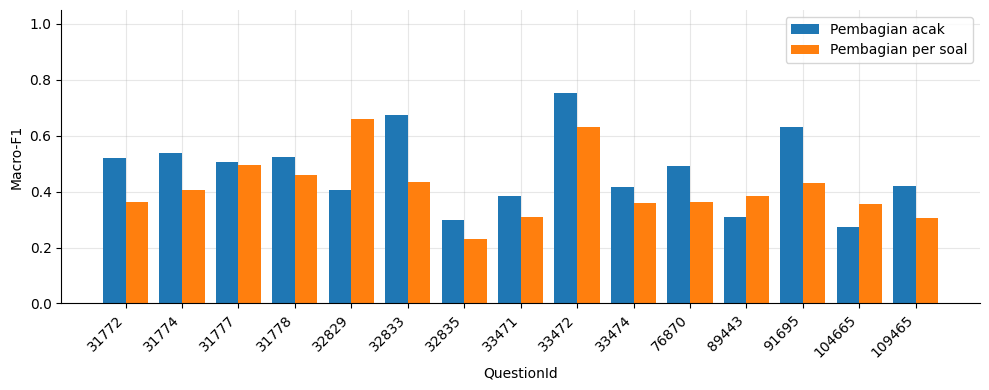

Rata-rata macro-F1 | acak: 0.4767 | per soal: 0.4129


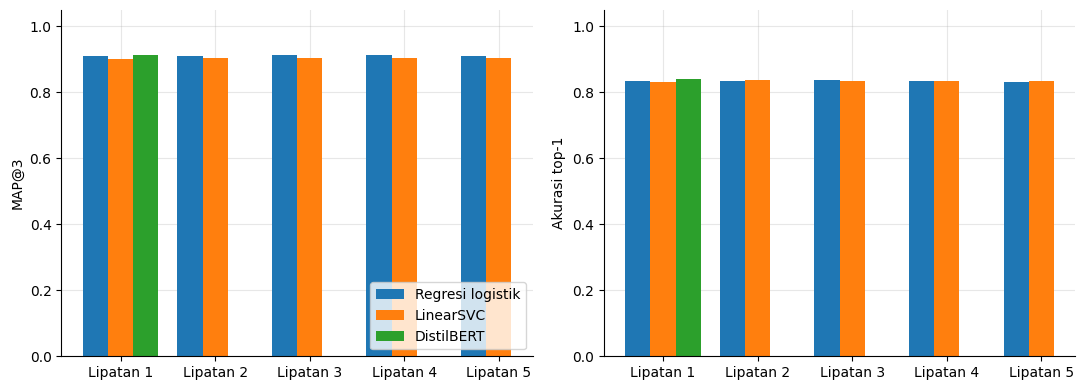

Gambar 3 dilewati: isi LOG_TEXT dengan log pelatihan DistilBERT.


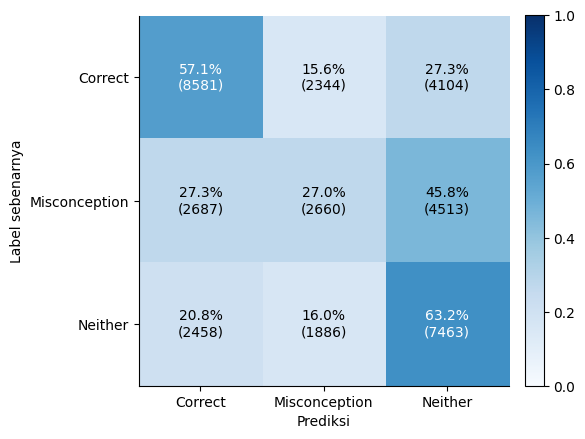

In [12]:
# ===== GAMBAR UNTUK MAKALAH =====
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import hstack
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, confusion_matrix

SIMPAN_GAMBAR = False       # True untuk menyimpan PNG ke folder output
DPI = 300

# Gambar 3: tempel log pelatihan DistilBERT di sini (baris "epoch x/3 | step n/T | loss L")
LOG_TEXT = """

"""

plt.rcParams.update({
    "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
})
CLASSES3 = ["Correct", "Misconception", "Neither"]


def selesai(fig, nama):
    fig.tight_layout()
    if SIMPAN_GAMBAR:
        fig.savefig(ROOT / f"{nama}.png", dpi=DPI, bbox_inches="tight")
    plt.show()


# ---------- Baseline ringan (tanpa fitur QuestionId agar adil di kedua pembagian) ----------
def target3(df):
    cat = df["Category"].astype(str)
    return np.where(cat.str.endswith("_Correct"), "Correct",
           np.where(cat.str.endswith("_Misconception"), "Misconception", "Neither"))


def oof_predict(df, y, splits):
    txt = text_context(df)
    expl = df["StudentExplanation"].astype(str).to_numpy()
    pred = np.empty(len(df), dtype=object)
    for tr_idx, va_idx in splits:
        word = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=.995, sublinear_tf=True,
                               max_features=20000, dtype=np.float32)
        char = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2,
                               sublinear_tf=True, max_features=5000, dtype=np.float32)
        Xtr = hstack([word.fit_transform(txt[tr_idx]), char.fit_transform(expl[tr_idx]) * 0.5], format="csr")
        Xva = hstack([word.transform(txt[va_idx]), char.transform(expl[va_idx]) * 0.5], format="csr")
        clf = LogisticRegression(C=1.0, solver="lbfgs", max_iter=200, tol=1e-2, random_state=42)
        clf.fit(Xtr, y[tr_idx])
        pred[va_idx] = clf.predict(Xva)
    return pred.astype(str)


fig_df = train_data.reset_index(drop=True)
y3 = target3(fig_df)
qids = fig_df["QuestionId"].astype(str).to_numpy()
expl_groups = fig_df["StudentExplanation"].map(norm_text).to_numpy()

t0 = time.time()
print("Menjalankan pembagian acak (grup penjelasan) ...")
split_acak = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
                  .split(fig_df, fig_df["Category"].astype(str), expl_groups))
pred_acak = oof_predict(fig_df, y3, split_acak)

print("Menjalankan pembagian per soal (GroupKFold berdasarkan QuestionId) ...")
split_soal = list(GroupKFold(n_splits=5).split(fig_df, y3, qids))
pred_soal = oof_predict(fig_df, y3, split_soal)
print(f"Selesai dalam {time.time() - t0:.1f} detik")

# ---------- Gambar 1: macro-F1 per soal ----------
soal_list = sorted(set(qids), key=lambda s: int(s) if s.isdigit() else s)
f1_acak, f1_soal = [], []
for q in soal_list:
    m = qids == q
    f1_acak.append(f1_score(y3[m], pred_acak[m], average="macro", zero_division=0))
    f1_soal.append(f1_score(y3[m], pred_soal[m], average="macro", zero_division=0))

x = np.arange(len(soal_list))
w = 0.4
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - w/2, f1_acak, w, label="Pembagian acak")
ax.bar(x + w/2, f1_soal, w, label="Pembagian per soal")
ax.set_xticks(x)
ax.set_xticklabels(soal_list, rotation=45, ha="right")
ax.set_xlabel("QuestionId")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1.05)
ax.legend()
selesai(fig, "gambar1_macroF1_per_soal")
print(f"Rata-rata macro-F1 | acak: {np.mean(f1_acak):.4f} | per soal: {np.mean(f1_soal):.4f}")

# ---------- Gambar 2: MAP@3 dan top-1 per lipatan ----------
metrik = {}
if "cv_results" in globals():
    metrik["Regresi logistik"] = (cv_results["MAP@3"].to_numpy(), cv_results["Top1 Accuracy"].to_numpy())
else:
    print("cv_results (regresi logistik) tidak ditemukan, jalankan cell 4.")

if "scores" in globals() and len(scores) > 0 and isinstance(scores[0], tuple):
    metrik["LinearSVC"] = (np.array([s[0] for s in scores]), np.array([s[1] for s in scores]))
else:
    print("scores (LinearSVC) tidak ditemukan, jalankan cell 6.")

if "fold_results" in globals() and len(fold_results) > 0:
    fr = pd.DataFrame(fold_results)
    metrik["DistilBERT"] = (fr["MAP@3"].to_numpy(), fr["Top1_Accuracy"].to_numpy())
else:
    print("fold_results (DistilBERT) tidak ditemukan, jalankan cell DistilBERT.")

if metrik:
    n_fold = max(len(v[0]) for v in metrik.values())
    nm = len(metrik)
    w = 0.8 / nm
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, idx, nama_metrik in zip(axes, (0, 1), ("MAP@3", "Akurasi top-1")):
        for k, (nama, vals) in enumerate(metrik.items()):
            v = np.full(n_fold, np.nan)
            v[:len(vals[idx])] = vals[idx]
            ax.bar(np.arange(n_fold) + (k - (nm - 1) / 2) * w, v, w, label=nama)
        ax.set_xticks(np.arange(n_fold))
        ax.set_xticklabels([f"Lipatan {i+1}" for i in range(n_fold)])
        ax.set_ylabel(nama_metrik)
        ax.set_ylim(0, 1.05)
    axes[0].legend(loc="lower right")
    selesai(fig, "gambar2_metrik_per_lipatan")

# ---------- Gambar 3: kurva loss DistilBERT ----------
pola = re.compile(r"epoch\s+(\d+)/(\d+)\s*\|\s*step\s+(\d+)/(\d+)\s*\|\s*loss\s+([0-9.]+)")
baris = pola.findall(LOG_TEXT)
if baris:
    steps = np.array([int(b[2]) for b in baris])
    loss = np.array([float(b[4]) for b in baris])
    total_epoch = int(baris[0][1])
    total_steps = int(baris[0][3])
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(steps, loss, marker="o", markersize=3, linewidth=1.5)
    for e in range(1, total_epoch):
        ax.axvline(total_steps * e / total_epoch, color="gray", linestyle="--", linewidth=1)
    ax.set_xlabel("Langkah pelatihan")
    ax.set_ylabel("Loss pelatihan")
    selesai(fig, "gambar3_kurva_loss")
else:
    print("Gambar 3 dilewati: isi LOG_TEXT dengan log pelatihan DistilBERT.")

# ---------- Gambar 4: matriks konfusi baseline (pembagian per soal) ----------
cm = confusion_matrix(y3, pred_soal, labels=CLASSES3)
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.grid(False)
ax.set_xticks(range(3)); ax.set_xticklabels(CLASSES3)
ax.set_yticks(range(3)); ax.set_yticklabels(CLASSES3)
ax.set_xlabel("Prediksi")
ax.set_ylabel("Label sebenarnya")
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm_norm[i, j]*100:.1f}%\n({cm[i, j]})", ha="center", va="center",
                color="white" if cm_norm[i, j] > 0.5 else "black")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
selesai(fig, "gambar4_matriks_konfusi")